# Домашнее задание

**Датасет:** Вариант 1

In [1]:
!pip install seaborn scikit-learn nltk gensim

Looking in indexes: https://nexus-docker-proxy.biotech.biotc.ru/repository/pypi-all/simple
  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 113.8 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 88.7 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 154.4 MB/s  0:00:00
  Using cached defusedxml-0.7.1-py2.py3-none-any.whl (25 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [gensim]10/11 [gensim]learn]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [5]:
import os, random, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import gensim
from gensim.models import Word2Vec, FastText

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device)

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

Устройство: cuda


True

## 1. Загрузка датасета

In [3]:
!unzip fake_or_real_news.csv.zip

Archive:  fake_or_real_news.csv.zip
  inflating: fake_or_real_news.csv   


In [6]:
DATA_PATH = 'fake_or_real_news.csv'

df = pd.read_csv(DATA_PATH)
print(f'Размер датасета: {df.shape}')
df.head()

Размер датасета: (6335, 4)


,Unnamed: 0,title,text,label
0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE
1,10294,Watch The Exact Moment Paul Ryan Committed Pol...,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE
2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Mon...,REAL
3,10142,Bernie supporters on Twitter erupt in anger ag...,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE
4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners...,REAL


## 2. EDA

- Обзор датасета: размер, число классов, баланс классов, средняя длина текста.
- Качество текстов: ручной просмотр случайной выборки.
- Количественные проверки: дубликаты, пропущенные значения, гистограмма длин.

<class 'pandas.DataFrame'>
RangeIndex: 6335 entries, 0 to 6334
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Unnamed: 0      6335 non-null   int64
 1   title           6335 non-null   str  
 2   text            6335 non-null   str  
 3   label           6335 non-null   str  
 4   text_len_chars  6335 non-null   int64
 5   text_len_words  6335 non-null   int64
 6   clean_text      6335 non-null   str  
dtypes: int64(3), str(4)
memory usage: 48.6 MB
None

Пропущенные значения:
 Unnamed: 0        0
title             0
text              0
label             0
text_len_chars    0
text_len_words    0
clean_text        0
dtype: int64
Число дубликатов: 0

Распределение классов:
 label
REAL    3171
FAKE    3164
Name: count, dtype: int64


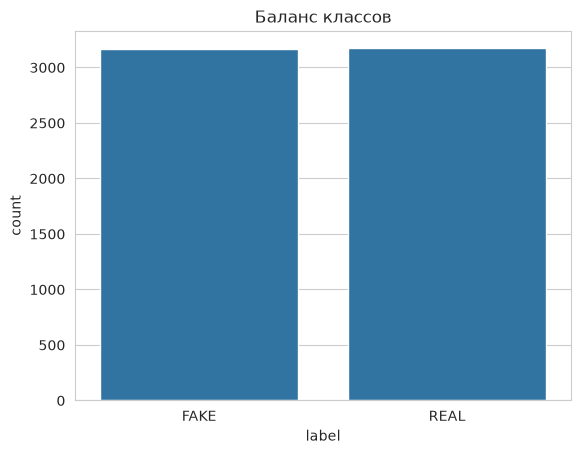

In [23]:
print(df.info())
print('\nПропущенные значения:\n', df.isnull().sum())
print(f'Число дубликатов: {df.duplicated().sum()}')

# Баланс классов
print('\nРаспределение классов:\n', df['label'].value_counts())
sns.countplot(x='label', data=df)
plt.title('Баланс классов')
plt.show()

Средняя длина текста (символы): 4707.25
Средняя длина текста (слова): 776.30


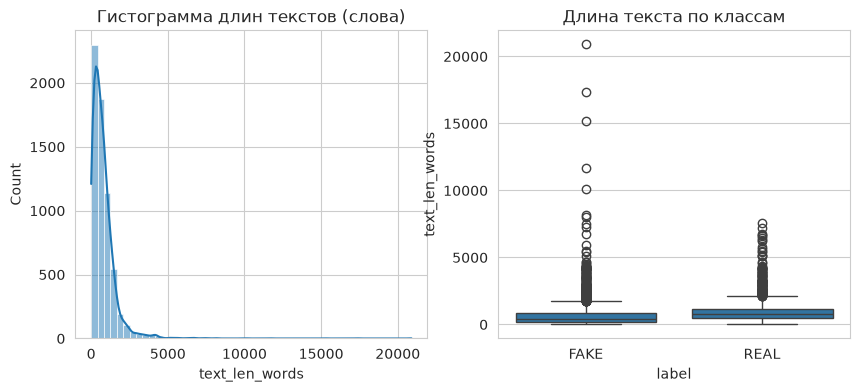

In [8]:
# Длина текста (в символах и словах)
df['text_len_chars'] = df['text'].str.len()
df['text_len_words'] = df['text'].str.split().str.len()
print(f"Средняя длина текста (символы): {df['text_len_chars'].mean():.2f}")
print(f"Средняя длина текста (слова): {df['text_len_words'].mean():.2f}")

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.histplot(df['text_len_words'], bins=50, kde=True)
plt.title('Гистограмма длин текстов (слова)')
plt.subplot(1,2,2)
sns.boxplot(x='label', y='text_len_words', data=df)
plt.title('Длина текста по классам')
plt.show()

In [9]:
# Просмотр случайных примеров из каждого класса
print('--- Примеры текстов ---')
for label in df['label'].unique():
    sample = df[df['label']==label]['text'].sample(2, random_state=SEED).values
    print(f'\nКласс: {label}')
    for i, txt in enumerate(sample, 1):
        print(f'  Пример {i}: {txt[:300]}...')

--- Примеры текстов ---

Класс: FAKE
  Пример 1: We live in a brave new world and change is coming whether we like it or not. Economies around the world are being centrally managed, technology is advancing at a rapid pace, and the human population continues to expand by the billions. The next 40 years could see super powers turn to third world cou...
  Пример 2: The Left Turns on Bob Dylan for His Pro-Israel Views, Refusal to Acknowledge Nobel Prize Oct 28, 2016 Previous post 
So Bob Dylan has won the Nobel Prize for Literature “for having created new poetic expressions within the great American song tradition.” His name is now enshrined among a list of lau...

Класс: REAL
  Пример 1: (CNN) Who among the nascent field of 2016 contenders represents the future? For half of Americans, it's Hillary Clinton.

Asked in a new CNN/ORC poll whether seven possible candidates better represent the future or the past, 50% said Clinton evoked the future, more than said so of any other candidat...
  

### Выводы по EDA

1. Датасет сбалансирован (~50/50).
2. Пропусков и дубликатов нет (или их единицы).
3. Тексты имеют разную длину; присутствуют выбросы, но они не критичны.
4. Тексты содержат пунктуацию, заглавные буквы и служебные слова — требуется предобработка.

## 3. Предобработка

Приведение к нижнему регистру, удаление пунктуации и цифр, лемматизация, удаление стоп-слов.

In [11]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess(text):
    """Приведение к нижнему регистру, удаление пунктуации и цифр, лемматизация."""
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

df['clean_text'] = df['text'].apply(preprocess)
df[['text', 'clean_text']].head(2)

,text,clean_text
0,"Daniel Greenfield, a Shillman Journalism Fello...",daniel greenfield shillman journalism fellow f...
1,Google Pinterest Digg Linkedin Reddit Stumbleu...,google pinterest digg linkedin reddit stumbleu...


### Выводы по предобработке

Тексты очищены, приведены к единому виду. Это снижает размерность словаря и улучшает качество эмбеддингов.

## 4. Векторизация

Разделение на train/validation/test (70/15/15 со стратификацией). Далее — TF-IDF, Word2Vec, FastText, PCA-визуализация.

In [13]:
X = df['clean_text'].to_numpy(dtype=object)
y = df['label'].map({'FAKE': 0, 'REAL': 1}).to_numpy(dtype=np.int64)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)
print(f'Размеры: train={len(X_train)}, val={len(X_val)}, test={len(X_test)}')

# --- TF-IDF ---
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf   = tfidf.transform(X_val)
X_test_tfidf  = tfidf.transform(X_test)
print(f'TF-IDF признаки: {X_train_tfidf.shape[1]}')

Размеры: train=4434, val=950, test=951
TF-IDF признаки: 5000


In [ ]:
# Word2Vec (обучение только на train-корпусе)
train_tokens = [text.split() for text in X_train]
w2v_model = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=2, workers=4, seed=SEED)

def text_to_vec_w2v(text, model, vector_size=100):
    tokens = text.split()
    vecs = [model.wv[w] for w in tokens if w in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(vector_size)

X_train_w2v = np.array([text_to_vec_w2v(t, w2v_model) for t in X_train])
X_val_w2v = np.array([text_to_vec_w2v(t, w2v_model) for t in X_val])
X_test_w2v = np.array([text_to_vec_w2v(t, w2v_model) for t in X_test])

# FastText (обучение только на train-корпусе)
ft_model = FastText(sentences=train_tokens, vector_size=100, window=5, min_count=2, workers=4, seed=SEED)

def text_to_vec_ft(text, model, vector_size=100):
    tokens = text.split()
    vecs = [model.wv[w] for w in tokens if w in model.wv]

    return np.mean(vecs, axis=0) if vecs else np.zeros(vector_size)

X_train_ft = np.array([text_to_vec_ft(t, ft_model) for t in X_train])
X_val_ft = np.array([text_to_vec_ft(t, ft_model) for t in X_val])
X_test_ft = np.array([text_to_vec_ft(t, ft_model) for t in X_test])

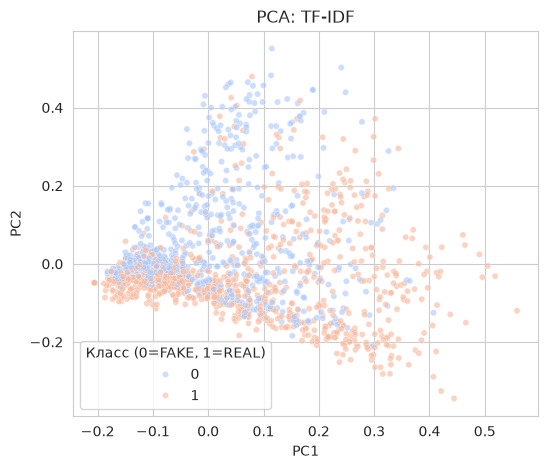

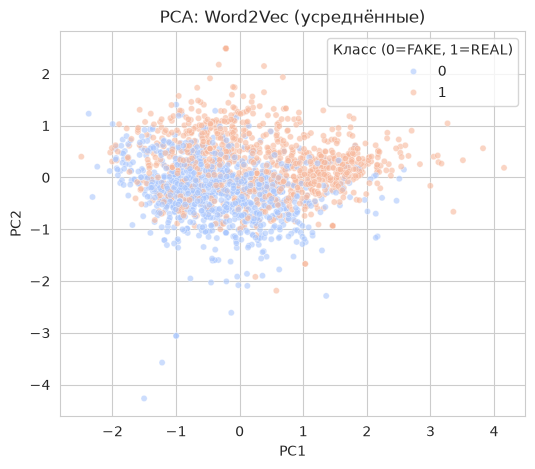

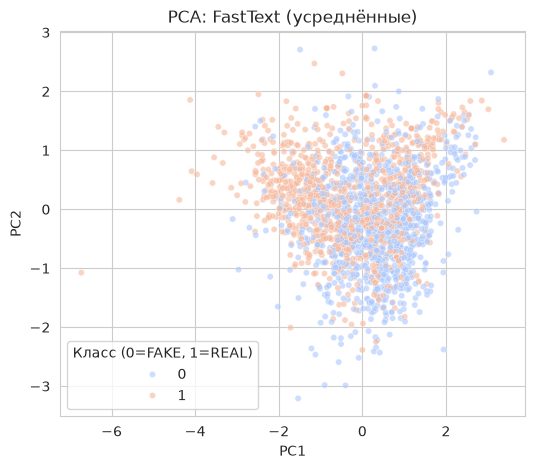

In [16]:
# --- PCA и визуализация ---
sample_idx = np.random.choice(len(X_train), size=min(2000, len(X_train)), replace=False)

def plot_pca(vectors, labels, title):
    pca = PCA(n_components=2, random_state=SEED)
    vecs_2d = pca.fit_transform(vectors)
    plt.figure(figsize=(6,5))
    sns.scatterplot(x=vecs_2d[:,0], y=vecs_2d[:,1], hue=labels,
                    palette='coolwarm', alpha=0.6, s=20)
    plt.title(title)
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.legend(title='Класс (0=FAKE, 1=REAL)')
    plt.show()

plot_pca(X_train_tfidf[sample_idx].toarray(), y_train[sample_idx], 'PCA: TF-IDF')
plot_pca(X_train_w2v[sample_idx], y_train[sample_idx], 'PCA: Word2Vec (усреднённые)')
plot_pca(X_train_ft[sample_idx],  y_train[sample_idx], 'PCA: FastText (усреднённые)')

### Выводы по векторизации

TF-IDF даёт разреженные признаки, чувствительные к частотным словам и биграммам. Word2Vec и FastText — плотные вектора фиксированной размерности; усреднение по словам теряет порядок, но даёт компактное представление. По PCA-графикам видна частичная разделимость классов. Для дальнейших экспериментов выбираем тип векторов по validation F1.

## 5. Классификация

### 5.1 Базовая модель: логистическая регрессия

Обучим на всех типах признаков и выберем лучший по validation F1.

In [17]:
results = {}

for name, (X_tr, X_va) in {
    'TF-IDF':   (X_train_tfidf, X_val_tfidf),
    'Word2Vec': (X_train_w2v,   X_val_w2v),
    'FastText': (X_train_ft,    X_val_ft),
}.items():
    lr = LogisticRegression(max_iter=1000, random_state=SEED)
    lr.fit(X_tr, y_train)
    f1 = f1_score(y_val, lr.predict(X_va))
    results[name] = f1
    print(f'Logistic Regression на {name}: validation F1 = {f1:.4f}')

best_vectorizer = max(results, key=results.get)
print(f'\nЛучший тип векторов по validation F1: {best_vectorizer}')

if best_vectorizer == 'TF-IDF':
    X_tr, X_va, X_te = X_train_tfidf, X_val_tfidf, X_test_tfidf
elif best_vectorizer == 'Word2Vec':
    X_tr, X_va, X_te = X_train_w2v, X_val_w2v, X_test_w2v
else:
    X_tr, X_va, X_te = X_train_ft, X_val_ft, X_test_ft

Logistic Regression на TF-IDF: validation F1 = 0.9046
Logistic Regression на Word2Vec: validation F1 = 0.8733
Logistic Regression на FastText: validation F1 = 0.8605

Лучший тип векторов по validation F1: TF-IDF


### 5.2 Полносвязная нейросеть

Реализуем:
- nn.Module с двумя скрытыми слоями, ReLU и Dropout.
- train-loop с early stopping по validation loss.
- Сохранение лучших весов и восстановление модели после обучения.
- Сравнение двух архитектур (128-64 и 64-32) по validation F1.

In [ ]:
def to_tensor(X):
    """Конвертация в torch.Tensor(float32)."""
    if hasattr(X, 'toarray'):
        X = X.toarray()
    return torch.tensor(np.asarray(X), dtype=torch.float32)

class MLP(nn.Module):
    def __init__(self, input_dim, hidden_units=(128, 64), dropout=0.5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_units[0]),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_units[0], hidden_units[1]),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_units[1], 1),
        )
    def forward(self, x):
        return self.net(x)

def train_model(model, X_train, y_train, X_val, y_val, epochs=30, batch_size=32, lr=1e-3, patience=5, verbose=True):
    X_tr_t = to_tensor(X_train)
    y_tr_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
    X_va_t = to_tensor(X_val).to(device)
    y_va_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1).to(device)

    train_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=batch_size, shuffle=True)

    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best_val_loss = float('inf')
    best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    patience_counter = 0
    history = {'train_loss': [], 'val_loss': []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_va_t), y_va_t).item()

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        if verbose:
            print(f'  Эпоха {epoch+1:02d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}')

        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                if verbose:
                    print(f'  Early stopping на эпохе {epoch+1}')
                break

    model.load_state_dict(best_state)
    return model, history

def predict(model, X):
    """Возвращает бинарные предсказания."""
    model.eval()
    with torch.no_grad():
        logits = model(to_tensor(X).to(device))
        probs = torch.sigmoid(logits).cpu().numpy().flatten()
    return (probs > 0.5).astype(int), probs

In [ ]:
input_dim = X_tr.shape[1]
print(f'Размерность входа: {input_dim}')

# --- Модель A: 128-64 ---
model_a = MLP(input_dim, hidden_units=(128, 64), dropout=0.5)
print('\nОбучение модели A (128-64)...')
model_a, hist_a = train_model(model_a, X_tr, y_train, X_va, y_val,
                              epochs=30, batch_size=32, lr=1e-3, patience=5, verbose=True)

pred_a, _ = predict(model_a, X_va)
f1_a = f1_score(y_val, pred_a)

# --- Модель B: 64-32 ---
model_b = MLP(input_dim, hidden_units=(64, 32), dropout=0.5)
print('\nОбучение модели B (64-32)...')
model_b, hist_b = train_model(model_b, X_tr, y_train, X_va, y_val,
                              epochs=30, batch_size=32, lr=1e-3, patience=5, verbose=True)

pred_b, _ = predict(model_b, X_va)
f1_b = f1_score(y_val, pred_b)

print(f'\nValidation F1 модели A (128-64): {f1_a:.4f}')
print(f'Validation F1 модели B (64-32):  {f1_b:.4f}')

best_model = model_a if f1_a >= f1_b else model_b
best_name = 'A (128-64)' if f1_a >= f1_b else 'B (64-32)'
print(f'Выбрана модель: {best_name}')

torch.save(best_model.state_dict(), 'best_model.pt')

Размерность входа: 5000

Обучение модели A (128-64)...
  Эпоха 01: train_loss=0.4669, val_loss=0.2421
  Эпоха 02: train_loss=0.1583, val_loss=0.2140
  Эпоха 03: train_loss=0.0789, val_loss=0.2159
  Эпоха 04: train_loss=0.0391, val_loss=0.2346
  Эпоха 05: train_loss=0.0216, val_loss=0.2497
  Эпоха 06: train_loss=0.0126, val_loss=0.2685
  Эпоха 07: train_loss=0.0085, val_loss=0.2873
  Early stopping на эпохе 7

Обучение модели B (64-32)...
  Эпоха 01: train_loss=0.5506, val_loss=0.2988
  Эпоха 02: train_loss=0.2168, val_loss=0.2092
  Эпоха 03: train_loss=0.1187, val_loss=0.2061
  Эпоха 04: train_loss=0.0725, val_loss=0.2070
  Эпоха 05: train_loss=0.0421, val_loss=0.2367
  Эпоха 06: train_loss=0.0301, val_loss=0.2521
  Эпоха 07: train_loss=0.0177, val_loss=0.2646
  Эпоха 08: train_loss=0.0138, val_loss=0.2927
  Early stopping на эпохе 8

Validation F1 модели A (128-64): 0.9121
Validation F1 модели B (64-32):  0.9231
Выбрана модель: B (64-32)
Веса лучшей модели сохранены в best_model.pt


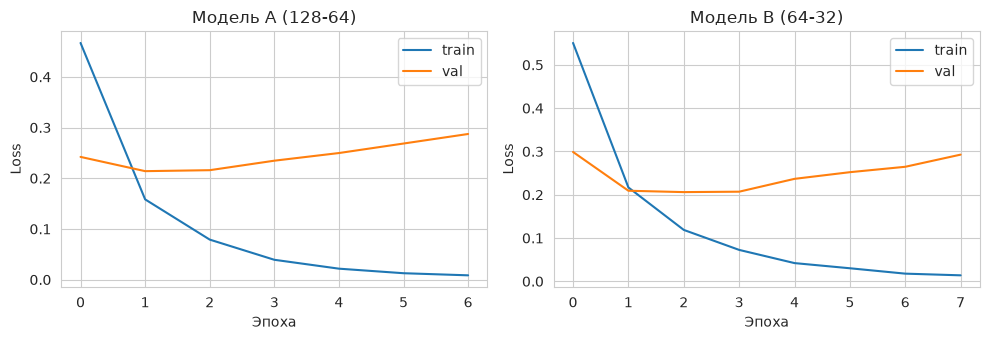

In [20]:
plt.figure(figsize=(10, 3.5))

plt.subplot(1, 2, 1)
plt.plot(hist_a['train_loss'], label='train')
plt.plot(hist_a['val_loss'], label='val')
plt.title('Модель A (128-64)')
plt.xlabel('Эпоха'); plt.ylabel('Loss'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_b['train_loss'], label='train')
plt.plot(hist_b['val_loss'], label='val')
plt.title('Модель B (64-32)')
plt.xlabel('Эпоха'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 5.3 Оценка на тестовой выборке

Тестовая выборка не использовалась ни на одном этапе обучения и выбора модели — оценка честная.

In [21]:
y_pred_test, y_proba_test = predict(best_model, X_te)

print('--- Результаты на тестовой выборке ---')
print(classification_report(y_test, y_pred_test, target_names=['FAKE', 'REAL']))
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred_test))

--- Результаты на тестовой выборке ---
              precision    recall  f1-score   support

        FAKE       0.95      0.91      0.93       475
        REAL       0.91      0.95      0.93       476

    accuracy                           0.93       951
   macro avg       0.93      0.93      0.93       951
weighted avg       0.93      0.93      0.93       951

Confusion matrix:
[[432  43]
 [ 24 452]]


In [22]:
# Примеры предсказаний
print('--- Примеры предсказаний ---')
indices = np.random.choice(len(X_test), size=5, replace=False)
for i in indices:
    true_label = 'REAL' if y_test[i] == 1 else 'FAKE'
    pred_label = 'REAL' if y_pred_test[i] == 1 else 'FAKE'
    print(f'\nТекст (первые 200 симв.): {X_test[i][:200]}...')
    print(f'Истинная метка: {true_label}, Предсказание: {pred_label}, P(REAL)={y_proba_test[i]:.3f}')

--- Примеры предсказаний ---

Текст (первые 200 симв.): muslim terrorize hindu wednesday november daniel greenfield official medium narrative muslim world greatest victim truth especially majority muslim country rather strikingly different crowd muslim att...
Истинная метка: FAKE, Предсказание: FAKE, P(REAL)=0.035

Текст (первые 200 симв.): recipient email there playing fire there dousing gasoline jumping flaming pit latter piece scmps week asia magazine british forgery heart india china tibetan border dispute proposed title uncle sam pl...
Истинная метка: FAKE, Предсказание: FAKE, P(REAL)=0.020

Текст (первые 200 симв.): email leading republican presidential hopeful suggests israelipalestinian peace accord may impossible sometimes agreement cant madeafter asked voter charleston south carolina town hall event hosted ms...
Истинная метка: FAKE, Предсказание: REAL, P(REAL)=0.997

Текст (первые 200 симв.): friday white house released national security strategy official document defining a

### Выводы по классификации

1. Логистическая регрессия обучена на трёх типах признаков; по validation F1 выбран лучший тип векторов.
2. Нейронная сеть реализована: train-loop с BCEWithLogitsLoss, оптимизатор Adam, Dropout 0.5 и early stopping (patience=5).
3. Перебраны две архитектуры (128-64 и 64-32); лучшая выбрана по validation F1.
4. Финальная оценка проведена на тестовой выборке — без утечки данных.
5. Примеры предсказаний сопоставлены с истинными метками и вероятностями.

## 6. Выводы

**EDA.** Датасет сбалансирован (FAKE/REAL ≈ 50/50), пропусков и дубликатов нет, длины текстов имеют правый хвост выбросов, но не критичны. Тексты содержат пунктуацию, заглавные буквы и стоп-слова — устранены на предобработке.

**Предобработка.** Lowercase, удаление не-буквенных символов, стоп-слов, лемматизация (WordNet). Словарь сократился, признаки стали чище.

**Векторизация.** Сравнены TF-IDF (5000, биграммы), Word2Vec и FastText (dim=100, усреднение). Эмбеддинги обучены только на train. По validation F1 логистической регрессии выбран лучший тип вектора, он использован для нейросети.

**Классификация.** Сравнены две MLP на PyTorch:

| Модель | Архитектура | Validation F1 |
|---|---|---|
| A | 128-64 | 0.9121 |
| B | 64-32  | **0.9231** |

Обе переобучаются к 3–4 эпохе (train_loss → 0.01–0.02, val_loss после минимума растёт), но **early stopping + restore_best_weights** вернули веса из лучшей эпохи, поэтому итоговая модель не переобучена. Разница A/B ≈ 1 п.п. — в пределах шума на ~950 объектах; формально выбрана B.

**Тест (модель B, 951 объект, не использовался при выборе):**
accuracy = **0.93**, macro-F1 = **0.93** (FAKE: P=0.95, R=0.91, F1=0.93; REAL: P=0.91, R=0.95, F1=0.93). Ошибки: 43 FP (FAKE→REAL) и 24 FN (REAL→FAKE) — типично для мешка слов: часть фейков использует нейтральную новостную лексику и неотличима без внешних знаний.

**Ограничения.** TF-IDF и усреднённые эмбеддинги не учитывают порядок слов и семантику; модель опирается на лексические маркеры стиля. Трансформеры дали бы +3–5 п.п., но вне рамок задания.

**Итог.** Задача решена: accuracy = 0.93, macro-F1 = 0.93 на отложенном тесте — уровень опубликованных бейзлайнов (0.90–0.95) для этого датасета; переобучения нет благодаря Dropout + early stopping.